In [1]:
import torch
from config import default_config as conf
from data import generate_data_tensor
from model import model
from training import trainer

torch.manual_seed(0)
X, Y = generate_data_tensor(conf)              # all 43**2 pairs, one-hot, shuffled
n_train = round(0.8 * len(X))
X_train, Y_train = X[:n_train], Y[:n_train]
X_test,  Y_test  = X[n_train:], Y[n_train:]

net = model(conf)                              # also opens a TensorBoard writer in runs/
t = trainer(net)

In [2]:
torch.where(X[1])
torch.where(Y[1])

(tensor([0, 1, 2]), tensor([41,  5,  3]))

In [3]:
def accuracy(net, X, Y):
    with torch.no_grad():
        return (net(X)[:, -1].argmax(-1) == Y[:, -1].argmax(-1)).float().mean().item()

for epoch in range(3000):
    t.train(X_train, Y_train)                  # one full-batch AdamW step, logs train/loss
    t.test(X_test, Y_test)                     # logs test/loss, no weight update
    if epoch % 100 == 0:
        print(epoch, accuracy(net, X_train, Y_train), accuracy(net, X_test, Y_test))

0 0.02366463840007782 0.021621622145175934
100 0.15551048517227173 0.0
200 0.9966193437576294 0.029729729518294334
300 1.0 0.07027027010917664
400 1.0 0.1621621549129486
500 1.0 0.2405405342578888
600 1.0 0.4000000059604645
700 1.0 0.5972973108291626
800 1.0 0.7567567825317383
900 1.0 0.862162172794342
1000 1.0 0.9243243336677551
1100 1.0 0.9783783555030823
1200 1.0 0.9945945739746094
1300 1.0 0.9972972869873047
1400 1.0 0.9972972869873047
1500 1.0 1.0
1600 1.0 1.0
1700 1.0 1.0
1800 1.0 1.0
1900 1.0 1.0
2000 1.0 1.0
2100 1.0 1.0
2200 1.0 1.0
2300 1.0 1.0
2400 1.0 1.0
2500 1.0 1.0
2600 1.0 1.0
2700 1.0 1.0
2800 1.0 1.0
2900 1.0 1.0


In [ ]:
#torch.save(net.state_dict(), "nardo_model_43.pt")
# later: net = model(conf); net.load_state_dict(torch.load("nardo_model_43.pt"))

In [9]:
net.W_Q.shape

torch.Size([4, 128, 32])

In [11]:
import numpy as np
import matplotlib.pyplot as plt

def plot_vector_and_dft(v, title):
    """Scatter the entries of a real vector v, then the magnitudes of its DFT."""
    v = np.asarray(v, dtype=float)
    n = len(v)
    idx = np.arange(n)
    F = np.fft.fft(v)

    fig, (ax_v, ax_f) = plt.subplots(1, 2, figsize=(11, 3.4))

    ax_v.plot(idx, v, linestyle=":", linewidth=1, color="#2a78d6", alpha=0.35)
    ax_v.scatter(idx, v, s=18, color="#2a78d6")
    ax_v.set(title=title, xlabel="index", ylabel="value")

    ax_f.vlines(idx, 0, np.abs(F), color="#2a78d6", alpha=0.35, linewidth=1)
    ax_f.scatter(idx, np.abs(F), s=18, color="#2a78d6")
    ax_f.set(title=f"DFT magnitude ({n} coefficients)", xlabel="frequency k", ylabel="|F_k|")

    for ax in (ax_v, ax_f):
        ax.grid(alpha=0.25)
    fig.tight_layout()
    plt.show()
    return F



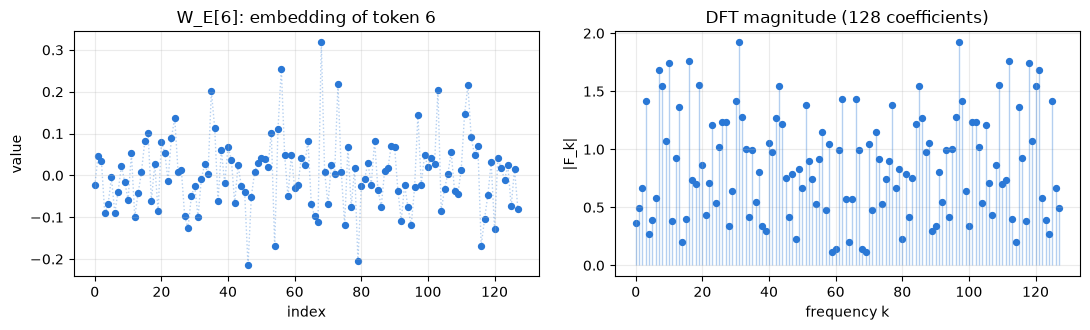

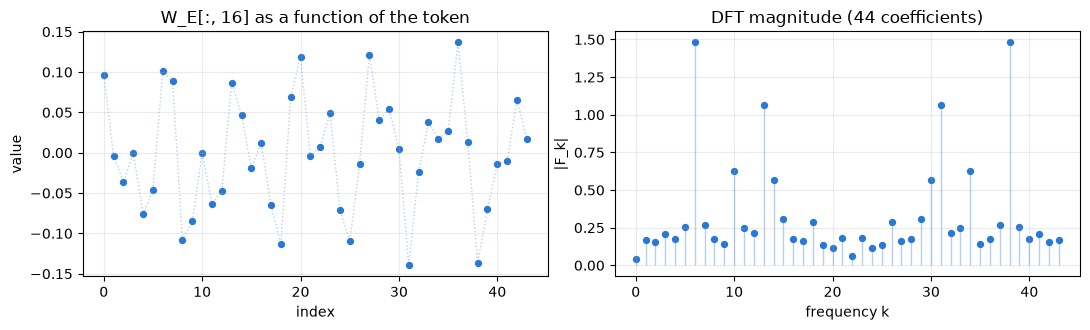

In [25]:


W_E = net.W_E.detach().cpu().numpy()        # (d_vocab, d_model) = (44, 128)

i = 6                                     # a token: row of W_E, 128 entries
F_row = plot_vector_and_dft(W_E[i], f"W_E[{i}]: embedding of token {i}")

j +=1                                    # a residual dimension: column of W_E, 44 entries
F_col = plot_vector_and_dft(W_E[:, j], f"W_E[:, {j}] as a function of the token")

In [13]:
import torch
from config import default_config as conf
from encoding import encode_string

x = encode_string(conf, "1 5")          # (3, 44): one-hot rows for 1, 5, and '?'
x = x.unsqueeze(0)                      # (1, 3, 44): batch of one question

with torch.no_grad():
    logits = net(x)                     # (1, 3, 44)

answer_logits = logits[0, -1]           # the 44 logits at the '?' position
probs = answer_logits.softmax(dim=-1)

print("prediction:", answer_logits.argmax().item(), "   truth:", (1 + 5) % conf.modulus)
print("P(answer = 6):", probs[6].item())
print("top 5 tokens:", probs.topk(5))

prediction: 6    truth: 6
P(answer = 6): 0.999091625213623
top 5 tokens: torch.return_types.topk(
values=tensor([9.9909e-01, 2.9571e-04, 2.0388e-04, 1.6431e-04, 9.4548e-05]),
indices=tensor([ 6, 27, 20, 13, 36]))


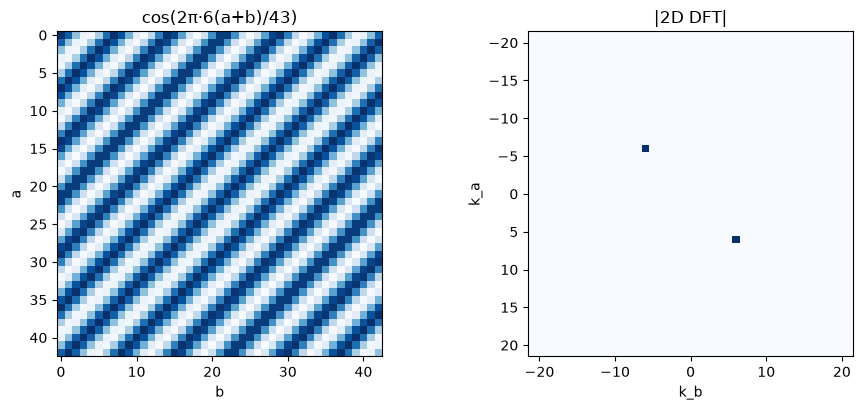

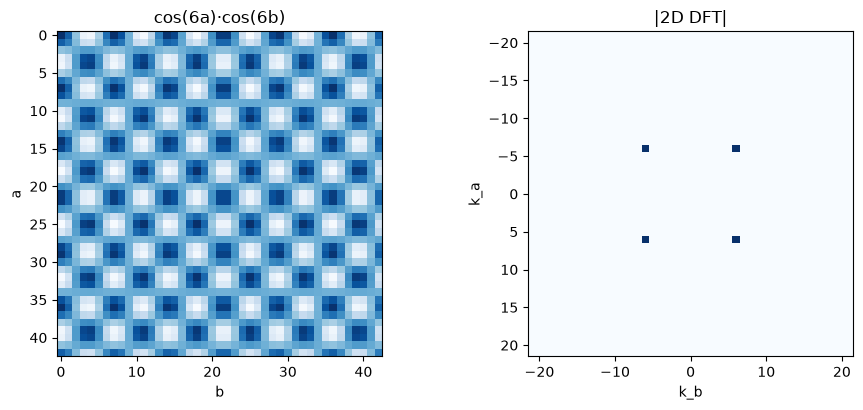

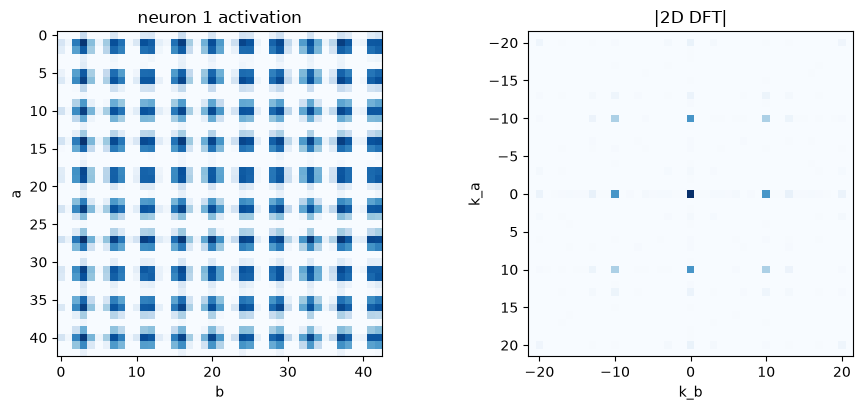

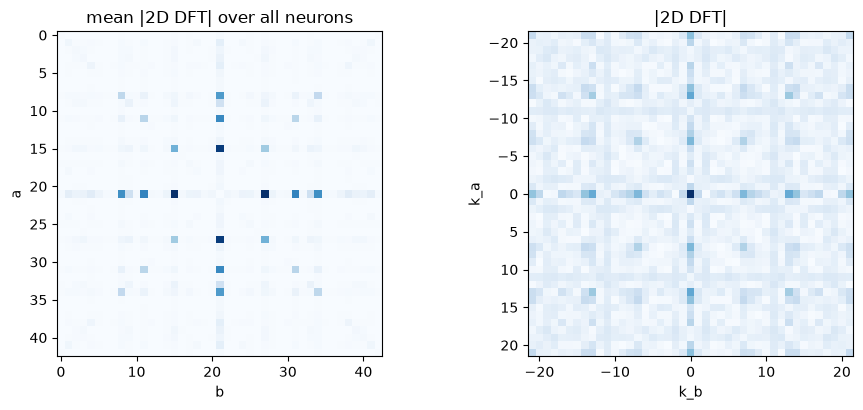

fraction of spectral energy on the diagonal k_a = k_b: 0.115521654


In [ ]:
import dataclasses
import numpy as np
import torch
import matplotlib.pyplot as plt
from encoding import encode_tensor
from loss import loss_fn
from model import model
from embedding import embedding
from attention import attention
from unembedding import unembedding

N = conf.modulus
A_grid, B_grid = torch.meshgrid(torch.arange(N), torch.arange(N), indexing="ij")
all_ids = torch.stack([A_grid.flatten(), B_grid.flatten(), torch.full((N * N,), N)], dim=-1)  # (N², 3)
X_all = encode_tensor(conf, all_ids)                                                           # (N², 3, 44)
C_all = (A_grid + B_grid) % N                                                                  # (N, N) true answers

@torch.no_grad()
def hidden_activations(net, X):
    "MLP hidden layer at the '?' position: (batch, d_mlp)."
    x1 = attention(net, embedding(net, X))
    return torch.relu(x1[:, -1] @ net.W_i + net.b_i)

@torch.no_grad()
def eval_metrics(net, X, Y):
    "Answer-token loss and accuracy."
    logits = net(X)
    loss = loss_fn(Y, logits).item()
    acc = (logits[:, -1].argmax(-1) == Y[:, -1].argmax(-1)).float().mean().item()
    return loss, acc

#2D DFT of neuron activations:

def plot_2d_dft(grid, title):
    "grid: (N, N) real array indexed [a, b]. Plot it and |2D DFT| with frequency 0 at the center."
    F = np.fft.fftshift(np.fft.fft2(grid))
    half = N // 2
    fig, (ax_g, ax_f) = plt.subplots(1, 2, figsize=(9.5, 4.2))
    ax_g.imshow(grid, cmap="Blues")
    ax_g.set(title=title, xlabel="b", ylabel="a")
    ax_f.imshow(np.abs(F), cmap="Blues", extent=(-half - .5, half + .5, half + .5, -half - .5))
    ax_f.set(title="|2D DFT|", xlabel="k_b", ylabel="k_a")
    for ax in (ax_g, ax_f):
        ax.grid(False)
    fig.tight_layout()
    plt.show()

# calibration: what known functional forms look like
a = np.arange(N)[:, None]
b = np.arange(N)[None, :]
plot_2d_dft(np.cos(2 * np.pi * 6 * (a + b) / N), "cos(2π·6(a+b)/43)")
plot_2d_dft(np.cos(2 * np.pi * 6 * a / N) * np.cos(2 * np.pi * 6 * b / N), "cos(6a)·cos(6b)")

# real neurons
H = hidden_activations(net, X_all).numpy().reshape(N, N, -1)   # indexed [a, b, neuron]
neuron = 1
plot_2d_dft(H[:, :, neuron], f"neuron {neuron} activation")

# the whole layer at once
F_all = np.abs(np.fft.fftshift(np.fft.fft2(H, axes=(0, 1)), axes=(0, 1)))   # (N, N, d_mlp)
F_all[N // 2, N // 2, :] = 0                                                 # drop each neuron's mean
plot_2d_dft(F_all.mean(-1), "mean |2D DFT| over all neurons")
diag = np.eye(N, dtype=bool)
print("fraction of spectral energy on the diagonal k_a = k_b:", (F_all[diag] ** 2).sum() / (F_all ** 2).sum())


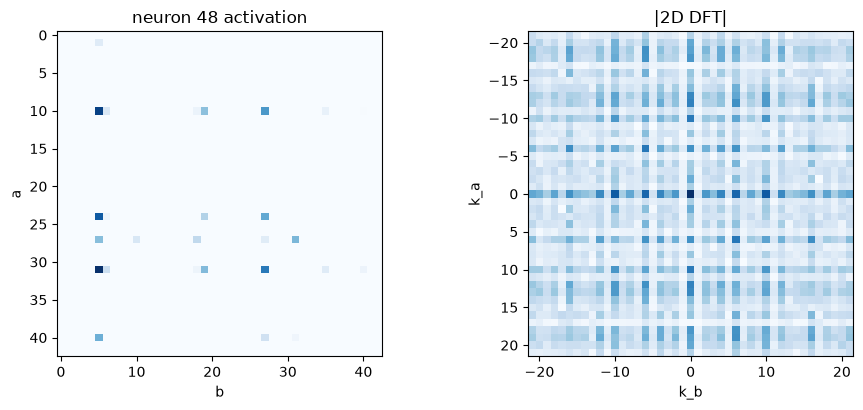

In [81]:
neuron +=1
plot_2d_dft(H[:, :, neuron], f"neuron {neuron} activation")

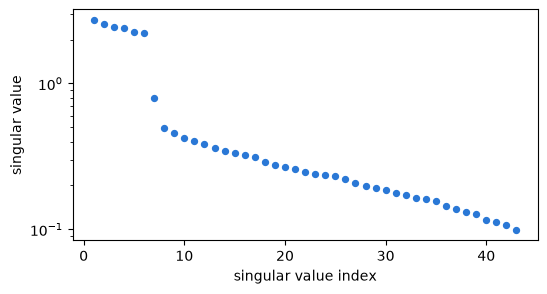

fraction of ||W_E[:43]||² in the top 7 singular directions: 0.93566525


In [82]:
E = net.W_E.detach().numpy()[:N]
S = np.linalg.svd(E, compute_uv=False)
fig, ax = plt.subplots(figsize=(6, 3))
ax.scatter(np.arange(1, len(S) + 1), S, s=18, color="#2a78d6")
ax.set(yscale="log", xlabel="singular value index", ylabel="singular value")
plt.show()
print("fraction of ||W_E[:43]||² in the top 7 singular directions:", (S[:7] ** 2).sum() / (S ** 2).sum())

In [ ]:
def train_and_record(net, steps, log_every=25):
    hist = {k: [] for k in ("step", "train_loss", "test_loss", "train_acc", "test_acc")}
    for step in range(steps + 1):
        if step % log_every == 0 or step == steps:
            (tr_loss, tr_acc), (te_loss, te_acc) = eval_metrics(net, X_train, Y_train), eval_metrics(net, X_test, Y_test)
            for key, val in zip(hist, (step, tr_loss, te_loss, tr_acc, te_acc)):
                hist[key].append(val)
        if step < steps:
            net.train(X_train, Y_train)
    return hist

def plot_histories(histories, key):
    "histories: {name: hist}. key: 'loss' or 'acc'. Solid = train, dashed = test."
    fig, ax = plt.subplots(figsize=(7.5, 3.6))
    for (name, h), color in zip(histories.items(), ["#2a78d6", "#eb6834", "#3aa655", "#8e5bd0"]):
        ax.plot(h["step"], h[f"train_{key}"], color=color, lw=1.5, label=f"{name}, train")
        ax.plot(h["step"], h[f"test_{key}"], color=color, lw=1.5, ls="--", label=f"{name}, test")
    ax.set(xlabel="optimizer step", ylabel=key, yscale="log" if key == "loss" else "linear")
    ax.legend(fontsize=8)
    plt.show()